# Noria · 03 — Baseline models (experiments E1, E2, E3)

Session 3: first models, run **exactly** as pre-registered in `docs/experiments.md`.

- **E1** — Baseline: logistic regression vs LightGBM on `BANK_NO_HISTORY_FEATURES`.
- **E2** — Cost of the history: LightGBM with history vs LightGBM without history (paired bootstrap).
- **E3** — Client model viability: LightGBM on `CLIENT_FEATURES` (logistic regression shown for reference).

All models are fitted on the **train** set only; all metrics are computed on the **validation** set.
**The test set is never loaded in this notebook.** The logic lives in `src/train.py`, `src/evaluate.py` and `src/experiments.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

from src import config, data, experiments, train as tr, evaluate as ev

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=120, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{name}")

## 0. The test set is locked

In [2]:
try:
    data.load_split("test")
except data.TestSetLockedError as error:
    print("As expected:", error)

As expected: The test set is locked until the final evaluation. Use load_split('test', final=True) only for the final results.


## 1. Train the five models and run E1, E2, E3

LightGBM: number of trees chosen by early stopping in a 5-fold stratified CV **on the train set**,
then refitted on the whole train set. No hyperparameter search in this session.

In [3]:
run = experiments.run_all()
results, val = run["results"], run["val"]
y_val = val[config.TARGET].to_numpy()
print(f"train rows: {len(run['train']):,} · validation rows: {len(val):,} · validation default rate: {y_val.mean():.2%}")

train rows: 194,762 · validation rows: 41,735 · validation default rate: 8.35%


## 2. Summary (validation set)

In [4]:
summary = pd.DataFrame([
    {
        "model": key.split("__")[0],
        "feature set": r["metrics"]["feature_set"],
        "features": len(r["features"]),
        "ROC-AUC": round(r["metrics"]["roc_auc"], 4),
        "95% CI": f"[{r['metrics']['ci_low']:.4f}, {r['metrics']['ci_high']:.4f}]",
        "PR-AUC": round(r["metrics"]["pr_auc"], 4),
        "trees": r["metrics"]["training"].get("n_estimators", "-"),
    }
    for key, r in results.items()
])
print(f"PR-AUC of a random model = default rate = {y_val.mean():.4f}")
summary

PR-AUC of a random model = default rate = 0.0835


,model,feature set,features,ROC-AUC,95% CI,PR-AUC,trees
0,logreg,bank_no_history,53,0.6698,"[0.6594, 0.6789]",0.1641,-
1,lgbm,bank_no_history,53,0.7093,"[0.6993, 0.7184]",0.1947,253
2,lgbm,bank_with_history,66,0.7663,"[0.7579, 0.7742]",0.2592,392
3,lgbm,client,9,0.6883,"[0.6780, 0.6979]",0.1708,189
4,logreg,client,9,0.6181,"[0.6079, 0.6280]",0.1251,-


Figure saved: reports/figures/08_roc_curves_validation.png


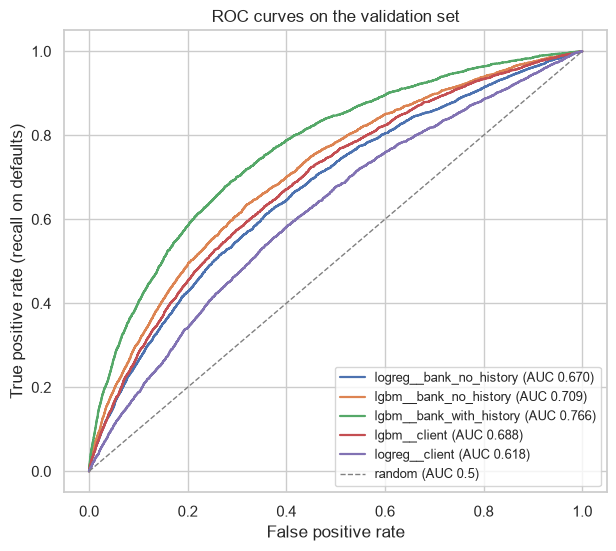

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for key, r in results.items():
    fpr, tpr, _ = roc_curve(y_val, r["p_val"])
    ax.plot(fpr, tpr, lw=1.6, label=f"{key} (AUC {r['metrics']['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1, label="random (AUC 0.5)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall on defaults)")
ax.set_title("ROC curves on the validation set")
ax.legend(loc="lower right", fontsize=9)
save(fig, "08_roc_curves_validation.png")
plt.show()

## 3. Experiments

In [6]:
e1 = run["e1"]
print("E1 — Baseline (BANK_NO_HISTORY_FEATURES)")
print(f"  logistic regression AUC: {e1['logreg_auc']:.4f}")
print(f"  LightGBM AUC:            {e1['lgbm_auc']:.4f}")
d = e1["lgbm_minus_logreg"]
print(f"  LightGBM - logreg: {d['auc_diff']:+.4f}  95% CI [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]  (paired bootstrap, {d['n_bootstrap']} resamples)")
print(f"  Rule: {e1['rule']}")
print(f"  Decision: {e1['decision']}")

E1 — Baseline (BANK_NO_HISTORY_FEATURES)
  logistic regression AUC: 0.6698
  LightGBM AUC:            0.7093
  LightGBM - logreg: +0.0396  95% CI [+0.0338, +0.0459]  (paired bootstrap, 1000 resamples)
  Rule: LightGBM must beat the logistic regression in validation AUC; otherwise, investigate
  Decision: LightGBM beats the logistic regression: LightGBM stays the main model


In [7]:
e2 = run["e2"]
d = e2["with_minus_without"]
print("E2 — Cost of the history (LightGBM)")
print(f"  with history AUC:    {e2['with_history_auc']:.4f}")
print(f"  without history AUC: {e2['no_history_auc']:.4f}")
print(f"  with - without: {d['auc_diff']:+.4f}  95% CI [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]  (paired bootstrap, {d['n_bootstrap']} resamples)")
print(f"  Rule: {e2['rule']}")

E2 — Cost of the history (LightGBM)
  with history AUC:    0.7663
  without history AUC: 0.7093
  with - without: +0.0569  95% CI [+0.0502, +0.0647]  (paired bootstrap, 1000 resamples)
  Rule: None: measurement to report


In [8]:
e3 = run["e3"]
print("E3 — Client model viability (CLIENT_FEATURES)")
print(f"  LightGBM AUC: {e3['client_lgbm_auc']:.4f}  95% CI [{e3['client_lgbm_ci'][0]:.4f}, {e3['client_lgbm_ci'][1]:.4f}]")
print(f"  logistic regression AUC (indicative): {e3['client_logreg_auc_indicative']:.4f}")
print(f"  Rule: {e3['rule']}")
print(f"  Decision: {e3['decision']}")

E3 — Client model viability (CLIENT_FEATURES)
  LightGBM AUC: 0.6883  95% CI [0.6780, 0.6979]
  logistic regression AUC (indicative): 0.6181
  Rule: >= 0.65 kept; 0.60-0.65 kept with a stronger caution message; < 0.60 dropped
  Decision: kept


## 4. Feature importance (LightGBM, gain)

Figure saved: reports/figures/09_feature_importance_gain.png


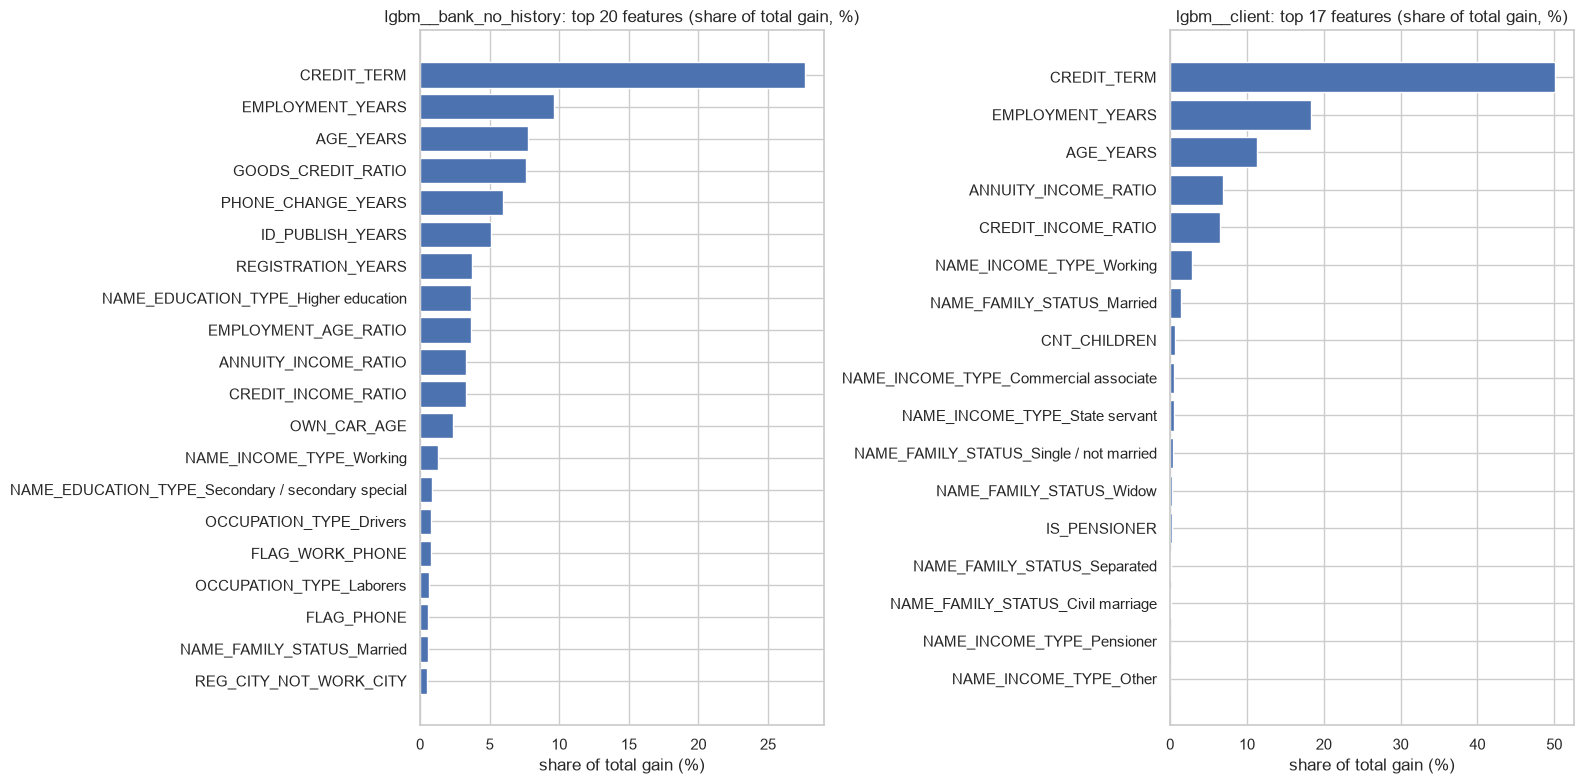

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
importances = {}
for ax, key in zip(axes, ["lgbm__bank_no_history", "lgbm__client"]):
    gain = tr.feature_importance(results[key]["pipeline"], "gain")
    share = (gain / gain.sum() * 100).round(2)
    importances[key] = pd.DataFrame({"gain": gain.round(0), "share (%)": share})
    top = share.head(20)[::-1]
    ax.barh(top.index, top.values, color="#4C72B0")
    ax.set_title(f"{key}: top {min(20, len(gain))} features (share of total gain, %)")
    ax.set_xlabel("share of total gain (%)")
fig.tight_layout()
save(fig, "09_feature_importance_gain.png")
plt.show()

In [10]:
print("lgbm__bank_no_history — top 20")
display(importances["lgbm__bank_no_history"].head(20))
print("lgbm__client — all features")
display(importances["lgbm__client"])

lgbm__bank_no_history — top 20


,gain,share (%)
CREDIT_TERM,105407.0,27.64
EMPLOYMENT_YEARS,36707.0,9.62
AGE_YEARS,29726.0,7.79
GOODS_CREDIT_RATIO,29098.0,7.63
PHONE_CHANGE_YEARS,22606.0,5.93
ID_PUBLISH_YEARS,19476.0,5.11
REGISTRATION_YEARS,14253.0,3.74
NAME_EDUCATION_TYPE_Higher education,13942.0,3.66
EMPLOYMENT_AGE_RATIO,13916.0,3.65
ANNUITY_INCOME_RATIO,12537.0,3.29


lgbm__client — all features


,gain,share (%)
CREDIT_TERM,134005.0,50.07
EMPLOYMENT_YEARS,49216.0,18.39
AGE_YEARS,30320.0,11.33
ANNUITY_INCOME_RATIO,18300.0,6.84
CREDIT_INCOME_RATIO,17283.0,6.46
NAME_INCOME_TYPE_Working,7769.0,2.90
NAME_FAMILY_STATUS_Married,3700.0,1.38
CNT_CHILDREN,1651.0,0.62
NAME_INCOME_TYPE_Commercial associate,1255.0,0.47
NAME_INCOME_TYPE_State servant,1184.0,0.44


## 5. Sanity checks

- **Leak**: a no-history model above 0.85 AUC, or a single feature dominating the gain (> 50%), must be investigated.
- **Overfitting**: train AUC vs validation AUC.

In [11]:
sanity = pd.DataFrame(run["sanity"]).set_index("model").round(4)
sanity

,train_auc,cv_auc_on_train_folds,val_auc,train_minus_val,overfit_flag,top_feature,top_feature_gain_share,dominant_feature_flag,leak_auc_flag
model,,,,,,,,,
logreg__bank_no_history,0.6695,NaN,0.6698,-0.0003,False,NaN,NaN,False,False
lgbm__bank_no_history,0.7646,0.7028,0.7093,0.0553,True,CREDIT_TERM,0.2764,False,False
lgbm__bank_with_history,0.8302,0.7618,0.7663,0.0640,True,EXT_SOURCE_3,0.2033,False,False
lgbm__client,0.7232,0.6842,0.6883,0.0350,False,CREDIT_TERM,0.5007,True,False
logreg__client,0.6184,NaN,0.6181,0.0003,False,NaN,NaN,False,False


### 5.1 Investigation: why does `CREDIT_TERM` dominate?

`CREDIT_TERM` (= `AMT_CREDIT / AMT_ANNUITY`) carries about half of the client model's gain.
Both amounts are known when the application is filed, so this is not a leak of the outcome.
We check on the **train set only** what the variable actually encodes.

In [12]:
train = run["train"]
term = train["CREDIT_TERM"]
ratio = (train["AMT_ANNUITY"] / train["AMT_CREDIT"]).round(4)
print(f"Distinct CREDIT_TERM values: {term.nunique():,} · distinct annuity / credit ratios (4 decimals): {ratio.nunique():,}")

rounded = term.round(2)
frequent = rounded.value_counts().head(8)
display(pd.DataFrame({
    "rows": frequent,
    "share (%)": (frequent / len(train) * 100).round(2),
    "default rate (%)": [round(train.loc[rounded == v, config.TARGET].mean() * 100, 2) for v in frequent.index],
}).rename_axis("CREDIT_TERM (rounded)"))

bands = train.groupby(pd.qcut(term, 20, duplicates="drop"), observed=True)[config.TARGET].mean().mul(100).round(2)
print(f"Default rate by CREDIT_TERM ventile: min {bands.min():.2f}% · max {bands.max():.2f}%")

Distinct CREDIT_TERM values: 33,508 · distinct annuity / credit ratios (4 decimals): 806


,rows,share (%),default rate (%)
CREDIT_TERM (rounded),,,
34.20,4461,2.29,5.27
34.06,2571,1.32,6.53
31.00,2328,1.20,8.16
34.08,2025,1.04,7.85
20.79,1784,0.92,8.74
23.60,1783,0.92,4.88
12.66,1659,0.85,17.78
19.59,1487,0.76,10.02


Default rate by CREDIT_TERM ventile: min 2.26% · max 15.68%


**Reading.** Annuities follow a grid of a few hundred annuity / credit ratios (combinations of duration and interest rate),
and neighbouring cells of this grid have very different default rates. `CREDIT_TERM` therefore most likely encodes
Home Credit's **pricing** (product and interest rate offered), which is itself based on the lender's risk assessment.
It is available at application time, so it is not a leak in the strict sense, but in the public client form
`CREDIT_TERM` is computed with an **assumed** interest rate (`ASSUMED_ANNUAL_INTEREST_RATE`): that pricing signal will not exist there.

## Findings

All metrics on the validation set (41,735 rows, 8.35% defaults); models fitted on train (194,762 rows). The test set was not loaded.

1. **Summary (ROC-AUC [95% bootstrap CI], PR-AUC)**:
   - logistic regression, bank without history (53 features): 0.6698 [0.6594, 0.6789], PR-AUC 0.1641
   - LightGBM, bank without history (53 features, 253 trees): **0.7093** [0.6993, 0.7184], PR-AUC 0.1947
   - LightGBM, bank with history (66 features, 392 trees): **0.7663** [0.7579, 0.7742], PR-AUC 0.2592
   - LightGBM, client (9 features, 189 trees): **0.6883** [0.6780, 0.6979], PR-AUC 0.1708
   - logistic regression, client (indicative): 0.6181 [0.6079, 0.6280], PR-AUC 0.1251

   For reference, a random model has a PR-AUC equal to the default rate (0.0835).
2. **E1 — Baseline**: LightGBM beats the logistic regression by +0.0396 AUC (paired bootstrap 95% CI [+0.0338, +0.0459], above 0 in 100% of the 1,000 resamples). Rule satisfied: LightGBM stays the main model.
3. **E2 — Cost of the history**: the bank model with history reaches 0.7663 vs 0.7093 without, a gap of **+0.0569** AUC (paired bootstrap 95% CI [+0.0502, +0.0647]). This is a measurement to report (no decision rule).
4. **E3 — Client model viability**: LightGBM client AUC 0.6883 [0.6780, 0.6979] ≥ 0.65, so the client model is **kept**. The lower bound of the CI is also above 0.65. The client logistic regression is much lower (0.6181).
5. **Feature importance (gain)**: `CREDIT_TERM` is the top feature in both models, with 27.64% of the gain in the bank model without history and **50.07%** in the client model. It is followed by `EMPLOYMENT_YEARS` (9.62% / 18.39%) and `AGE_YEARS` (7.79% / 11.33%). In the bank model, `GOODS_CREDIT_RATIO` comes 4th (7.63%).
6. **Leak check**: no model without history is above 0.85 AUC. `CREDIT_TERM` crosses the 50% dominance threshold in the client model, so it was investigated (section 5.1). It is computed from amounts known at application time, so it is not an outcome leak. However, annuities follow a grid of 806 distinct annuity / credit ratios, and default rates vary from 2.26% to 15.68% across `CREDIT_TERM` ventiles. The variable most likely encodes Home Credit's pricing (product and interest rate), which is itself risk-based. In the public form, `CREDIT_TERM` is computed with an assumed interest rate, so this signal will be absent: the client AUC of 0.6883 is probably optimistic for real use.
7. **Overfitting check**: train AUC vs validation AUC: bank without history 0.7646 vs 0.7093 (gap 0.0553), bank with history 0.8302 vs 0.7663 (0.0640), client 0.7232 vs 0.6883 (0.0350); the logistic regressions show no gap. The 5-fold CV AUC on train (0.7028, 0.7618, 0.6842) is close to the validation AUC, so the validation estimate is consistent. The in-sample train AUC is higher, as expected for boosting without tuning.